
# Fish Object Detection Using YOLOv8n

### Deep Learning | Computer Vision | Object Detection

---

**Project Type:** Object Detection

**Dataset:** Brackish Dataset

**Model:** YOLOv8n (Trained from Scratch)

**Framework:** PyTorch & Ultralytics

**Programming Language:** Python

**Execution Environment:** Visual Studio Code

---

## Project Overview

This project aims to develop an underwater object detection system capable of identifying and localizing different fish and marine object categories using Deep Learning.

The system utilizes the publicly available Brackish Dataset and a YOLOv8n architecture trained from scratch.

The complete pipeline includes dataset exploration, exploratory data analysis, data preprocessing, annotation preparation, model training, performance evaluation, and object detection visualization.



# Table of Contents

1. Project Introduction
2. Environment Setup and Configuration
3. Dataset Exploration
4. Exploratory Data Analysis (EDA)
5. Data Preprocessing
6. Dataset Preparation
7. Data Validation
8. YOLOv8n Model Architecture
9. Model Training
10. Training Results Analysis
11. Model Evaluation
12. Object Detection Predictions
13. Conclusion and Future Work



# 1. Project Introduction

## 1.1 Project Objectives

The main objectives of this project are:

- Explore and understand an external underwater object detection dataset.
- Analyze image distributions and object annotations.
- Prepare and preprocess the dataset for YOLO training.
- Convert annotations into the required YOLO format.
- Split the dataset into training, validation, and testing sets.
- Build a YOLOv8n model from scratch without pretrained weights.
- Train the model using the prepared dataset.
- Evaluate model performance using standard object detection metrics.
- Visualize and analyze the final detection results.

## 1.2 Technologies and Libraries

- Python
- PyTorch
- Ultralytics YOLOv8
- OpenCV
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Pillow



# 2. Environment Setup and Configuration

This section prepares the execution environment, imports the required libraries, configures reproducibility settings, and verifies GPU availability for deep learning operations.


In [1]:

# Standard Libraries
import os
import sys
import random
import shutil
import json
from pathlib import Path

# Data Processing
import numpy as np
import pandas as pd

# Image Processing
import cv2
from PIL import Image

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Deep Learning
import torch
from ultralytics import YOLO

# Progress Monitoring
from tqdm.auto import tqdm

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

print("All required libraries imported successfully!")


All required libraries imported successfully!


c:\Users\20109\miniconda3\envs\fish-detection\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

# Set random seed for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed configured successfully:", SEED)


Random seed configured successfully: 42


In [3]:

# Check GPU availability
DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Python Version:", sys.version.split()[0])
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("Selected Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 2),
        "GB"
    )


Python Version: 3.12.16
PyTorch Version: 2.14.1+cu130
CUDA Available: True
Selected Device: 0
GPU Name: NVIDIA GeForce RTX 3050 Laptop GPU
GPU Memory: 4.0 GB


In [4]:

if torch.cuda.is_available():

    x = torch.rand(1000, 1000, device="cuda")
    y = torch.rand(1000, 1000, device="cuda")

    z = torch.matmul(x, y)

    print("GPU Computation Test: PASSED")
    print("Tensor Device:", z.device)

    del x, y, z
    torch.cuda.empty_cache()

else:
    print("GPU Computation Test: NOT AVAILABLE")


GPU Computation Test: PASSED
Tensor Device: cuda:0



# 3. Dataset Exploration

This section explores the Brackish Dataset to understand its directory structure, identify available data files, and inspect the annotation resources.

The dataset exploration process helps us understand the available images, videos, annotation files, and class information before starting data preprocessing.


In [5]:

# Define project directory
PROJECT_ROOT = Path.cwd()

# Define dataset directory
DATASET_ROOT = PROJECT_ROOT / "archive"

# Define processed data directory
PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"

# Create output directory
PROCESSED_ROOT.mkdir(parents=True, exist_ok=True)

print("Project Root:", PROJECT_ROOT)
print("Dataset Root:", DATASET_ROOT)
print("Processed Data Root:", PROCESSED_ROOT)

# Verify dataset directory
if DATASET_ROOT.exists():
    print("\nDataset directory found successfully!")
else:
    raise FileNotFoundError(
        f"Dataset directory not found: {DATASET_ROOT}"
    )


Project Root: c:\Users\20109\Downloads\Fish Detection
Dataset Root: c:\Users\20109\Downloads\Fish Detection\archive
Processed Data Root: c:\Users\20109\Downloads\Fish Detection\data\processed

Dataset directory found successfully!


In [6]:

# Display the main dataset directories and files

print("Brackish Dataset Structure\n")

for item in sorted(DATASET_ROOT.iterdir()):
    if item.is_dir():
        print(f"[DIR]  {item.name}")
    else:
        print(f"[FILE] {item.name}")


Brackish Dataset Structure

[DIR]  annotations
[DIR]  dataset
[DIR]  scripts
[FILE] test.txt
[FILE] train.txt
[FILE] valid.txt


In [7]:

# Initialize file categories
file_extensions = {}

# Scan dataset files
for file_path in DATASET_ROOT.rglob("*"):

    if file_path.is_file():

        extension = file_path.suffix.lower()

        if extension == "":
            extension = "No Extension"

        file_extensions[extension] = (
            file_extensions.get(extension, 0) + 1
        )

# Create summary DataFrame
files_summary = pd.DataFrame(
    file_extensions.items(),
    columns=["File Extension", "Number of Files"]
)

files_summary = files_summary.sort_values(
    by="Number of Files",
    ascending=False
).reset_index(drop=True)

display(files_summary)


,File Extension,Number of Files
0,.txt,15087
1,.avi,89
2,.json,6
3,.py,5
4,.csv,3
5,.names,1
6,.bat,1
7,.sh,1


In [8]:

# Common video formats
VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv"}

# Annotation formats
ANNOTATION_EXTENSIONS = {".json", ".csv", ".txt", ".xml"}

# Collect video files
video_files = [
    path for path in DATASET_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in VIDEO_EXTENSIONS
]

# Collect annotation files
annotation_files = [
    path for path in DATASET_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in ANNOTATION_EXTENSIONS
]

print("Dataset File Summary")
print("-" * 40)

print("Total Video Files:", len(video_files))
print("Total Annotation Files:", len(annotation_files))

print("\nAnnotation Files:")

for file_path in annotation_files[:30]:
    print(file_path.relative_to(DATASET_ROOT))

if len(annotation_files) > 30:
    print(f"... and {len(annotation_files) - 30} more files")


Dataset File Summary
----------------------------------------
Total Video Files: 89
Total Annotation Files: 15096

Annotation Files:
test.txt
train.txt
valid.txt
annotations\annotations_AAU\test.csv
annotations\annotations_AAU\train.csv
annotations\annotations_AAU\valid.csv
annotations\annotations_COCO\test_groundtruth.json
annotations\annotations_COCO\test_helper_dirs.json
annotations\annotations_COCO\train_groundtruth.json
annotations\annotations_COCO\train_helper_dirs.json
annotations\annotations_COCO\valid_groundtruth.json
annotations\annotations_COCO\valid_helper_dirs.json
annotations\annotations_YOLO\2019-02-20_19-01-02to2019-02-20_19-01-13_1-0001.txt
annotations\annotations_YOLO\2019-02-20_19-01-02to2019-02-20_19-01-13_1-0002.txt
annotations\annotations_YOLO\2019-02-20_19-01-02to2019-02-20_19-01-13_1-0003.txt
annotations\annotations_YOLO\2019-02-20_19-01-02to2019-02-20_19-01-13_1-0004.txt
annotations\annotations_YOLO\2019-02-20_19-01-02to2019-02-20_19-01-13_1-0005.txt
annotation

In [9]:

# Display the main dataset directory structure

print("DATASET DIRECTORY OVERVIEW")
print("=" * 50)

for folder in sorted(DATASET_ROOT.iterdir()):

    if folder.is_dir():
        total_files = sum(1 for f in folder.rglob("*") if f.is_file())

        print(f"\nFolder: {folder.name}")
        print(f"Total Files: {total_files}")

    else:
        print(f"File: {folder.name}")


DATASET DIRECTORY OVERVIEW

Folder: annotations
Total Files: 15093

Folder: dataset
Total Files: 89

Folder: scripts
Total Files: 8
File: test.txt
File: train.txt
File: valid.txt


In [10]:

# Inspect available annotation directories

ANNOTATIONS_ROOT = DATASET_ROOT / "annotations"

if ANNOTATIONS_ROOT.exists():

    annotation_sources = []

    for folder in sorted(ANNOTATIONS_ROOT.iterdir()):

        if folder.is_dir():

            total_files = sum(
                1 for f in folder.rglob("*") if f.is_file()
            )

            annotation_sources.append({
                "Annotation Format": folder.name,
                "Number of Files": total_files
            })

    annotation_summary = pd.DataFrame(annotation_sources)

    display(annotation_summary)

else:
    print("Annotations directory not found.")


,Annotation Format,Number of Files
0,annotations_AAU,3
1,annotations_COCO,6
2,annotations_YOLO,15084


In [11]:

# Search for class definition files

class_files = list(DATASET_ROOT.rglob("*.names"))

print("Class Definition Files:")
print("-" * 40)

for file in class_files:
    print(file.relative_to(DATASET_ROOT))

# Display class names if available
if class_files:

    CLASS_FILE = class_files[0]

    with open(CLASS_FILE, "r", encoding="utf-8") as file:
        class_names = [
            line.strip()
            for line in file
            if line.strip()
        ]

    print("\nAvailable Classes:")
    for class_id, class_name in enumerate(class_names):
        print(f"{class_id}: {class_name}")

    print("\nTotal Classes:", len(class_names))

else:
    print("No .names file found.")


Class Definition Files:
----------------------------------------
scripts\Brackish.names

Available Classes:
0: fish
1: small_fish
2: crab
3: shrimp
4: jellyfish
5: starfish

Total Classes: 6


# 4. Exploratory Data Analysis (EDA)

In this section, we analyze the Brackish Dataset to understand its image distribution, annotation statistics, and object categories.

The analysis includes inspecting image samples, examining class distributions, and understanding the bounding box annotations.

In [12]:
# Define class names and their corresponding IDs

CLASS_NAMES = class_names
NUM_CLASSES = len(CLASS_NAMES)

CLASS_MAPPING = {
    class_id: class_name
    for class_id, class_name in enumerate(CLASS_NAMES)
}

print("Number of Classes:", NUM_CLASSES)
print("\nClass Mapping:")

for class_id, class_name in CLASS_MAPPING.items():
    print(f"{class_id}: {class_name}")

Number of Classes: 6

Class Mapping:
0: fish
1: small_fish
2: crab
3: shrimp
4: jellyfish
5: starfish


In [13]:

# Inspect the dataset directory structure

print("DATASET STRUCTURE")
print("=" * 60)

for root, dirs, files in os.walk(DATASET_ROOT):

    level = len(Path(root).relative_to(DATASET_ROOT).parts)

    if level > 2:
        dirs.clear()
        continue

    indent = "    " * level

    print(f"\n{indent}{Path(root).name}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

    if len(files) > 5:
        print(f"{indent}    ... and {len(files) - 5} more files")


DATASET STRUCTURE

archive/
    test.txt
    train.txt
    valid.txt

    annotations/

        annotations_AAU/
            test.csv
            train.csv
            valid.csv

        annotations_COCO/
            test_groundtruth.json
            test_helper_dirs.json
            train_groundtruth.json
            train_helper_dirs.json
            valid_groundtruth.json
            ... and 1 more files

        annotations_YOLO/
            2019-02-20_19-01-02to2019-02-20_19-01-13_1-0001.txt
            2019-02-20_19-01-02to2019-02-20_19-01-13_1-0002.txt
            2019-02-20_19-01-02to2019-02-20_19-01-13_1-0003.txt
            2019-02-20_19-01-02to2019-02-20_19-01-13_1-0004.txt
            2019-02-20_19-01-02to2019-02-20_19-01-13_1-0005.txt
            ... and 15079 more files

    dataset/

        videos/

    scripts/
        AnnotationsToCOCO.py
        AnnotationsToYOLO.py
        Brackish.names
        createDummyYOLOAnnotations.py
        extractFrames_All.bat
        ...

In [14]:

# Display video file locations and extensions

print("VIDEO FILES INSPECTION")
print("=" * 60)

for video_path in video_files[:10]:
    print(video_path.relative_to(DATASET_ROOT))

print("\nTotal Videos:", len(video_files))

if video_files:
    print("\nFirst Video:")
    print(video_files[0])


VIDEO FILES INSPECTION
dataset\videos\crab\2019-02-22_22-31-28to2019-02-22_22-31-38_1.avi
dataset\videos\crab\2019-02-22_22-32-01to2019-02-22_22-32-15_1.avi
dataset\videos\crab\2019-03-06_22-01-00to2019-03-06_22-01-09_1.avi
dataset\videos\crab\2019-03-06_22-11-06to2019-03-06_22-11-17_1.avi
dataset\videos\crab\2019-03-06_22-12-29to2019-03-06_22-12-37_1.avi
dataset\videos\crab\2019-03-19_11-41-37to2019-03-19_11-41-47_1.avi
dataset\videos\crab\2019-03-19_11-42-13to2019-03-19_11-42-21_1.avi
dataset\videos\crab\2019-03-19_13-33-15to2019-03-19_13-33-25_1.avi
dataset\videos\crab\2019-03-19_19-56-16to2019-03-19_19-56-24_1.avi
dataset\videos\crab\2019-03-19_20-53-30to2019-03-19_20-53-39_1.avi

Total Videos: 89

First Video:
c:\Users\20109\Downloads\Fish Detection\archive\dataset\videos\crab\2019-02-22_22-31-28to2019-02-22_22-31-38_1.avi


In [15]:

# Locate YOLO annotation directory

YOLO_ANNOTATIONS_DIR = (
    DATASET_ROOT / "annotations" / "annotations_YOLO"
)

print("YOLO ANNOTATIONS")
print("=" * 60)

if YOLO_ANNOTATIONS_DIR.exists():

    yolo_files = list(YOLO_ANNOTATIONS_DIR.glob("*.txt"))

    print("YOLO Label Files:", len(yolo_files))

    if yolo_files:
        sample_label = yolo_files[0]

        print("\nSample Label File:", sample_label.name)

        print("\nLabel Content:")

        with open(sample_label, "r") as file:
            print(file.read()[:1000])

else:
    print("YOLO annotations directory not found.")


YOLO ANNOTATIONS
YOLO Label Files: 15084

Sample Label File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0001.txt

Label Content:



In [16]:
# Inspect dataset folders

DATASET_CONTENT_ROOT = DATASET_ROOT / "dataset"

print("DATASET SUBDIRECTORIES")
print("=" * 50)

for folder in sorted(DATASET_CONTENT_ROOT.iterdir()):

    if folder.is_dir():

        files = list(folder.iterdir())

        print(f"\nFolder: {folder.name}")
        print("Sub-items:", len(files))

        for item in files[:10]:
            print("  ", item.name)

DATASET SUBDIRECTORIES

Folder: videos
Sub-items: 5
   crab
   fish-big
   fish-school
   fish-small-shrimp
   jellyfish


In [17]:
# Inspect the original frame extraction script

EXTRACTION_SCRIPT = DATASET_ROOT / "extractFrames_All.bat"

if EXTRACTION_SCRIPT.exists():

    print("FRAME EXTRACTION SCRIPT")
    print("=" * 50)

    print(
        EXTRACTION_SCRIPT.read_text(
            encoding="utf-8",
            errors="replace"
        )
    )

else:
    print("Frame extraction script not found.")

Frame extraction script not found.


In [18]:
# Analyze empty and non-empty YOLO annotation files

yolo_files = sorted(YOLO_ANNOTATIONS_DIR.glob("*.txt"))

empty_labels = 0
non_empty_labels = 0
sample_non_empty = None

for label_path in yolo_files:

    content = label_path.read_text(
        encoding="utf-8"
    ).strip()

    if not content:
        empty_labels += 1

    else:
        non_empty_labels += 1

        if sample_non_empty is None:
            sample_non_empty = (label_path, content)

print("YOLO ANNOTATION STATISTICS")
print("=" * 50)

print("Total Label Files:", len(yolo_files))
print("Empty Labels:", empty_labels)
print("Non-empty Labels:", non_empty_labels)

if sample_non_empty:

    label_path, content = sample_non_empty

    print("\nSample Non-empty Label:")
    print("File:", label_path.name)
    print("Content:")
    print(content[:1000])

YOLO ANNOTATION STATISTICS
Total Label Files: 15084
Empty Labels: 4089
Non-empty Labels: 10995

Sample Non-empty Label:
File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0041.txt
Content:
2 6 516 13 17


In [19]:

# Search for dataset utility scripts

script_files = [
    path for path in DATASET_ROOT.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".py", ".bat", ".sh"}
]

print("AVAILABLE DATASET SCRIPTS")
print("=" * 50)

for script in script_files:
    print(script.relative_to(DATASET_ROOT))


AVAILABLE DATASET SCRIPTS
scripts\AnnotationsToCOCO.py
scripts\AnnotationsToYOLO.py
scripts\createDummyYOLOAnnotations.py
scripts\extractFrames_All.bat
scripts\extractFrames_All.sh
scripts\frameExtractor.py
scripts\VIAMEToCOCO.py


In [20]:

# Inspect original dataset split files

for split_name in ["train", "valid", "test"]:

    split_file = DATASET_ROOT / f"{split_name}.txt"

    print(f"\n{split_name.upper()} SPLIT")
    print("-" * 40)

    if split_file.exists():

        lines = [
            line.strip()
            for line in split_file.read_text(
                encoding="utf-8"
            ).splitlines()
            if line.strip()
        ]

        print("Number of entries:", len(lines))
        print("First 10 entries:")

        for line in lines[:10]:
            print(line)

    else:
        print("Split file not found.")



TRAIN SPLIT
----------------------------------------
Number of entries: 11739
First 10 entries:
2019-02-21_06-36-31to2019-02-21_06-36-39_1-0082.png
2019-02-22_22-11-57to2019-02-22_22-12-10_1-0065.png
2019-03-19_19-30-33to2019-03-19_19-30-45_1-0078.png
2019-03-19_17-02-04to2019-03-19_17-02-12_1-0063.png
2019-03-21_00-14-36to2019-03-21_00-14-49_1-0074.png
2019-03-21_03-21-54to2019-03-21_03-22-09_1-0099.png
2019-02-21_06-50-24to2019-02-21_06-50-40_1-0189.png
2019-03-19_14-02-47to2019-03-19_14-03-00_1-0074.png
2019-03-19_19-30-33to2019-03-19_19-30-45_1-0135.png
2019-03-19_18-15-37to2019-03-19_18-15-45_1-0015.png

VALID SPLIT
----------------------------------------
Number of entries: 1467
First 10 entries:
2019-02-21_06-52-16to2019-02-21_06-52-34_1-0039.png
2019-03-06_22-11-06to2019-03-06_22-11-17_1-0156.png
2019-02-22_23-27-24to2019-02-22_23-27-39_1-0043.png
2019-03-20_23-43-34to2019-03-20_23-43-42_1-0044.png
2019-03-06_22-27-01to2019-03-06_22-27-14_1-0002.png
2019-03-19_19-30-33to2019-0

In [21]:

# Inspect multiple non-empty YOLO annotation files

non_empty_samples = [
    path for path in yolo_files
    if path.stat().st_size > 0
][:10]

print("ANNOTATION FORMAT INSPECTION")
print("=" * 60)

for label_path in non_empty_samples:

    lines = [
        line.strip()
        for line in label_path.read_text(
            encoding="utf-8"
        ).splitlines()
        if line.strip()
    ]

    print(f"\nFile: {label_path.name}")

    for line in lines[:3]:
        values = line.split()
        print(
            "Values:", values,
            "| Number of values:", len(values)
        )


ANNOTATION FORMAT INSPECTION

File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0041.txt
Values: ['2', '6', '516', '13', '17'] | Number of values: 5

File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0042.txt
Values: ['2', '9', '516', '18', '22'] | Number of values: 5

File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0043.txt
Values: ['2', '11', '515', '22', '28'] | Number of values: 5

File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0044.txt
Values: ['2', '13', '514', '27', '33'] | Number of values: 5

File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0045.txt
Values: ['2', '15', '513', '31', '39'] | Number of values: 5

File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0046.txt
Values: ['2', '17', '513', '35', '39'] | Number of values: 5

File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0047.txt
Values: ['2', '19', '514', '39', '40'] | Number of values: 5

File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0048.txt
Values: ['2', '21', '513', '42', '41'] | Number of values: 5

File: 2019-0

In [22]:

# Compare video names with annotation names

print("VIDEO AND ANNOTATION NAME COMPARISON")
print("=" * 60)

print("\nVideo filenames:")

for video in video_files[:5]:
    print(video.stem)

print("\nYOLO annotation filenames:")

for label in yolo_files[:5]:
    print(label.stem)


VIDEO AND ANNOTATION NAME COMPARISON

Video filenames:
2019-02-22_22-31-28to2019-02-22_22-31-38_1
2019-02-22_22-32-01to2019-02-22_22-32-15_1
2019-03-06_22-01-00to2019-03-06_22-01-09_1
2019-03-06_22-11-06to2019-03-06_22-11-17_1
2019-03-06_22-12-29to2019-03-06_22-12-37_1

YOLO annotation filenames:
2019-02-20_19-01-02to2019-02-20_19-01-13_1-0001
2019-02-20_19-01-02to2019-02-20_19-01-13_1-0002
2019-02-20_19-01-02to2019-02-20_19-01-13_1-0003
2019-02-20_19-01-02to2019-02-20_19-01-13_1-0004
2019-02-20_19-01-02to2019-02-20_19-01-13_1-0005


In [23]:

# Search for extracted images across the project

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

excluded_dirs = {".venv", "__pycache__", ".git"}

all_project_images = []

for root, dirs, files in os.walk(PROJECT_ROOT):

    dirs[:] = [
        d for d in dirs
        if d not in excluded_dirs
    ]

    for filename in files:
        if Path(filename).suffix.lower() in IMAGE_EXTENSIONS:
            all_project_images.append(Path(root) / filename)

print("PROJECT IMAGE SEARCH")
print("=" * 50)

print("Total Images Found:", len(all_project_images))

for image_path in all_project_images[:15]:
    print(image_path.relative_to(PROJECT_ROOT))


PROJECT IMAGE SEARCH
Total Images Found: 0


In [24]:

# Load dataset split filenames

split_data = {}

for split_name in ["train", "valid", "test"]:

    split_file = DATASET_ROOT / f"{split_name}.txt"

    if split_file.exists():

        entries = [
            line.strip()
            for line in split_file.read_text(
                encoding="utf-8"
            ).splitlines()
            if line.strip()
        ]

        split_data[split_name] = entries

# Create annotation filename lookup
yolo_stems = {path.stem for path in yolo_files}

print("SPLIT AND ANNOTATION MATCHING")
print("=" * 50)

for split_name, entries in split_data.items():

    image_stems = {
        Path(entry).stem
        for entry in entries
    }

    matched = image_stems.intersection(yolo_stems)
    missing = image_stems - yolo_stems

    print(f"\n{split_name.upper()}")
    print("Images in split:", len(entries))
    print("Matching annotations:", len(matched))
    print("Missing annotations:", len(missing))

    if missing:
        print("Missing examples:", list(missing)[:5])


SPLIT AND ANNOTATION MATCHING

TRAIN
Images in split: 11739
Matching annotations: 11739
Missing annotations: 0

VALID
Images in split: 1467
Matching annotations: 1467
Missing annotations: 0

TEST
Images in split: 1468
Matching annotations: 1468
Missing annotations: 0


In [25]:

# Locate important dataset utility scripts

important_scripts = [
    "extractFrames_All.bat",
    "createDummyYOLOAnnotations.py"
]

print("DATASET UTILITY SCRIPTS")
print("=" * 50)

for script_name in important_scripts:

    matches = [
        path for path in DATASET_ROOT.rglob(script_name)
        if path.is_file()
    ]

    print(f"\n{script_name}:")

    if matches:
        for path in matches:
            print(path.relative_to(DATASET_ROOT))
    else:
        print("Not found")


DATASET UTILITY SCRIPTS

extractFrames_All.bat:
scripts\extractFrames_All.bat

createDummyYOLOAnnotations.py:
scripts\createDummyYOLOAnnotations.py


In [26]:

# Inspect the original frame extraction script

EXTRACTION_SCRIPT = (
    DATASET_ROOT / "scripts" / "extractFrames_All.bat"
)

if EXTRACTION_SCRIPT.exists():

    print("ORIGINAL FRAME EXTRACTION SCRIPT")
    print("=" * 60)

    script_content = EXTRACTION_SCRIPT.read_text(
        encoding="utf-8",
        errors="replace"
    )

    print(script_content)

else:
    print("Extraction script not found.")


ORIGINAL FRAME EXTRACTION SCRIPT
python frameExtractor.py -inputFolder ../dataset/crab
python frameExtractor.py -inputFolder ../dataset/fish-big
python frameExtractor.py -inputFolder ../dataset/fish-school
python frameExtractor.py -inputFolder ../dataset/fish-small-shrimp
python frameExtractor.py -inputFolder ../dataset/jellyfish



In [27]:

# Inspect the original annotation generation script

DUMMY_SCRIPT = (
    DATASET_ROOT / "scripts" / "createDummyYOLOAnnotations.py"
)

if DUMMY_SCRIPT.exists():

    print("ANNOTATION GENERATION SCRIPT")
    print("=" * 60)

    print(
        DUMMY_SCRIPT.read_text(
            encoding="utf-8",
            errors="replace"
        )
    )

else:
    print("Annotation generation script not found.")


ANNOTATION GENERATION SCRIPT
import os
import argparse

def createImageList(args):
    rootdir = args["inputFolder"]
    outputdir = os.path.abspath(args["outputFolder"])
    (_,_, curr_txt_files) = next(os.walk(outputdir))

    for root, _, files in os.walk(rootdir):
        for filename in files:
            filename_parts = os.path.splitext(filename)
            if filename_parts[-1] == ".png":
                txt_file = os.path.join(outputdir,filename_parts[0]+".txt")

                if os.path.basename(txt_file) not in curr_txt_files:
                    with open(txt_file, "w"):
                        pass

if __name__ == "__main__":
    ap = argparse.ArgumentParser( description = "Creates empty YOLO detection files for frames with no detections in it")
    ap.add_argument("-inputFolder", "--inputFolder", type=str, help="Path to the main folder holding all images")
    ap.add_argument("-outputFolder", "--outputFolder", type=str, help="Path to the output folder for the yolo .txt

In [28]:

# Locate and inspect the original frame extractor

extractor_files = list(
    DATASET_ROOT.rglob("frameExtractor.py")
)

print("FRAME EXTRACTOR INSPECTION")
print("=" * 60)

print("Files found:", len(extractor_files))

for extractor_path in extractor_files:

    print("\nFile:", extractor_path)

    extractor_code = extractor_path.read_text(
        encoding="utf-8",
        errors="replace"
    )

    print("\nOriginal Code:")
    print(extractor_code)


FRAME EXTRACTOR INSPECTION
Files found: 1

File: c:\Users\20109\Downloads\Fish Detection\archive\scripts\frameExtractor.py

Original Code:
import os
import subprocess
import argparse
import pathlib
import ipdb

image_types = ['.png', '.jpg', '.jpeg']
video_types = ['.avi', '.mp4']

def extractFrames(args):
    main_dir = args["inputFolder"]
    output_dir = args["outputFolder"]

    for sub_dir, dirs, files in os.walk(main_dir):
        for filename in files:
            if os.path.splitext(filename)[1].lower() in video_types:
                videoFile = os.path.join(os.path.abspath(sub_dir), filename)

                if output_dir != '':
                    fileFolder = output_dir
                else:
                    fileFolder = os.path.splitext(videoFile)[0]
                pathlib.Path(os.path.abspath(fileFolder)).mkdir(exist_ok=True, parents=True)

                fileprefix = os.path.join(fileFolder, os.path.splitext(filename)[0])

                cmd_command = ["ffmpeg", "

In [29]:

# Inspect video directories and their contents

video_root = DATASET_ROOT / "dataset" / "videos"

if video_root.exists():

    for class_folder in sorted(video_root.iterdir()):

        if class_folder.is_dir():

            videos = list(class_folder.glob("*.avi"))

            print(
                f"{class_folder.name}: "
                f"{len(videos)} videos"
            )

else:
    print("Video directory not found:", video_root)


crab: 17 videos
fish-big: 29 videos
fish-school: 9 videos
fish-small-shrimp: 22 videos
jellyfish: 12 videos


In [30]:

# Inspect the complete original frame extraction logic

extractor_path = extractor_files[0]

lines = extractor_path.read_text(
    encoding="utf-8",
    errors="replace"
).splitlines()

print("FRAME EXTRACTOR - COMPLETE SOURCE")
print("=" * 70)

for start in range(0, len(lines), 40):

    end = min(start + 40, len(lines))

    print(f"\nLines {start + 1} - {end}")
    print("-" * 70)

    for line_number in range(start, end):
        print(f"{line_number + 1:03}: {lines[line_number]}")


FRAME EXTRACTOR - COMPLETE SOURCE

Lines 1 - 40
----------------------------------------------------------------------
001: import os
002: import subprocess
003: import argparse
004: import pathlib
005: import ipdb
006: 
007: image_types = ['.png', '.jpg', '.jpeg']
008: video_types = ['.avi', '.mp4']
009: 
010: def extractFrames(args):
011:     main_dir = args["inputFolder"]
012:     output_dir = args["outputFolder"]
013: 
014:     for sub_dir, dirs, files in os.walk(main_dir):
015:         for filename in files:
016:             if os.path.splitext(filename)[1].lower() in video_types:
017:                 videoFile = os.path.join(os.path.abspath(sub_dir), filename)
018: 
019:                 if output_dir != '':
020:                     fileFolder = output_dir
021:                 else:
022:                     fileFolder = os.path.splitext(videoFile)[0]
023:                 pathlib.Path(os.path.abspath(fileFolder)).mkdir(exist_ok=True, parents=True)
024: 
025:                 filepre

In [31]:

# Display the missing extraction logic (Lines 14-42)

print("FRAME EXTRACTION LOGIC")
print("=" * 65)

for i in range(13, min(42, len(lines))):
    print(f"{i + 1:03}: {lines[i]}")


FRAME EXTRACTION LOGIC
014:     for sub_dir, dirs, files in os.walk(main_dir):
015:         for filename in files:
016:             if os.path.splitext(filename)[1].lower() in video_types:
017:                 videoFile = os.path.join(os.path.abspath(sub_dir), filename)
018: 
019:                 if output_dir != '':
020:                     fileFolder = output_dir
021:                 else:
022:                     fileFolder = os.path.splitext(videoFile)[0]
023:                 pathlib.Path(os.path.abspath(fileFolder)).mkdir(exist_ok=True, parents=True)
024: 
025:                 fileprefix = os.path.join(fileFolder, os.path.splitext(filename)[0])
026: 
027:                 cmd_command = ["ffmpeg", "-i", videoFile, "-vf", "scale=960:540", "-sws_flags", "bicubic", "{}-%04d.png".format(fileprefix), "-hide_banner"]
028:                 subprocess.call(cmd_command)
029: 
030:                 # Create a .txt file with the names of all the image files in the respective folder
031:         


## 4.5 Frame Extraction Preparation

The original dataset provides video files and YOLO annotations.

The original extraction pipeline uses FFmpeg to:
- Extract frames from AVI and MP4 videos.
- Resize frames to 960 × 540 pixels.
- Save frames in PNG format.
- Use filenames matching the original YOLO annotation files.

Before processing the complete dataset, we will verify FFmpeg availability and test the extraction process on one video.


In [32]:

# Check FFmpeg availability

import shutil
import subprocess

ffmpeg_path = shutil.which("ffmpeg")

if ffmpeg_path:

    print("FFmpeg Status: AVAILABLE")
    print("FFmpeg Path:", ffmpeg_path)

    result = subprocess.run(
        ["ffmpeg", "-version"],
        capture_output=True,
        text=True
    )

    print(result.stdout.splitlines()[0])

else:
    print("FFmpeg Status: NOT AVAILABLE")
    print("Please install FFmpeg before extraction.")


FFmpeg Status: NOT AVAILABLE
Please install FFmpeg before extraction.


In [34]:
import os
import subprocess
from pathlib import Path

FFMPEG_PATH = (
    Path(os.environ["LOCALAPPDATA"])
    / "Microsoft"
    / "WinGet"
    / "Packages"
    / "Gyan.FFmpeg.Shared_Microsoft.Winget.Source_8wekyb3d8bbwe"
    / "ffmpeg-9.0.2-full_build-shared"
    / "bin"
    / "ffmpeg.exe"
)

print("FFmpeg Exists:", FFMPEG_PATH.exists())

if FFMPEG_PATH.exists():
    result = subprocess.run(
        [str(FFMPEG_PATH), "-version"],
        capture_output=True,
        text=True
    )

    print("FFmpeg Status: AVAILABLE")
    print(result.stdout.splitlines()[0])
else:
    print("FFmpeg executable was not found.")

FFmpeg Exists: True
FFmpeg Status: AVAILABLE
ffmpeg version 9.0.2-full_build-www.gyan.dev Copyright (c) 2000-2026 the FFmpeg developers


In [35]:
# Find the first video in the Brackish dataset

VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv"}

video_files = [
    path for path in (DATASET_ROOT / "dataset" / "videos").rglob("*")
    if path.is_file() and path.suffix.lower() in VIDEO_EXTENSIONS
]

print("Total videos found:", len(video_files))

if video_files:
    test_video = video_files[0]
    print("Test video:", test_video)
    print("Video category:", test_video.parent.name)
else:
    print("No video files found!")

Total videos found: 89
Test video: c:\Users\20109\Downloads\Fish Detection\archive\dataset\videos\crab\2019-02-22_22-31-28to2019-02-22_22-31-38_1.avi
Video category: crab


In [36]:
# Extract frames from one test video

TEST_OUTPUT_DIR = PROJECT_ROOT / "data" / "test_extraction"
TEST_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

command = [
    str(FFMPEG_PATH),
    "-i", str(test_video),
    "-vf", "scale=960:540",
    "-sws_flags", "bicubic",
    str(TEST_OUTPUT_DIR / f"{test_video.stem}-%04d.png"),
    "-hide_banner"
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("Return Code:", result.returncode)

if result.returncode == 0:
    extracted_frames = list(TEST_OUTPUT_DIR.glob("*.png"))
    print("Extraction Successful!")
    print("Frames Extracted:", len(extracted_frames))
    print("Output Directory:", TEST_OUTPUT_DIR)
else:
    print("Extraction Failed!")
    print(result.stderr[-2000:])

Return Code: 0
Extraction Successful!
Frames Extracted: 145
Output Directory: c:\Users\20109\Downloads\Fish Detection\data\test_extraction


First 10 extracted frames:
2019-02-22_22-31-28to2019-02-22_22-31-38_1-0001.png
2019-02-22_22-31-28to2019-02-22_22-31-38_1-0002.png
2019-02-22_22-31-28to2019-02-22_22-31-38_1-0003.png
2019-02-22_22-31-28to2019-02-22_22-31-38_1-0004.png
2019-02-22_22-31-28to2019-02-22_22-31-38_1-0005.png
2019-02-22_22-31-28to2019-02-22_22-31-38_1-0006.png
2019-02-22_22-31-28to2019-02-22_22-31-38_1-0007.png
2019-02-22_22-31-28to2019-02-22_22-31-38_1-0008.png
2019-02-22_22-31-28to2019-02-22_22-31-38_1-0009.png
2019-02-22_22-31-28to2019-02-22_22-31-38_1-0010.png

Image Shape: (540, 960, 3)
Image Data Type: uint8


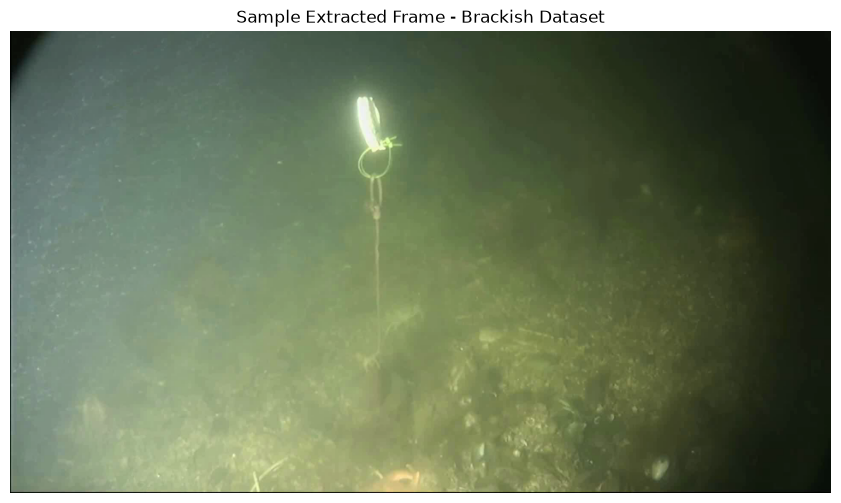

In [37]:
# Inspect extracted frames

print("First 10 extracted frames:")

for frame in sorted(extracted_frames)[:10]:
    print(frame.name)

# Load and display one frame
sample_image = cv2.imread(str(extracted_frames[0]))

print("\nImage Shape:", sample_image.shape)
print("Image Data Type:", sample_image.dtype)

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(sample_image, cv2.COLOR_BGR2RGB))
plt.title("Sample Extracted Frame - Brackish Dataset")
plt.axis("off")
plt.show()

### 4.6 Full Dataset Frame Extraction

In this step, frames will be extracted from all 89 videos in the Brackish Dataset using FFmpeg.

All frames will be resized to 960 × 540 pixels, following the original dataset extraction script.

The extracted frames will be stored separately while preserving their original filenames to maintain compatibility with the provided YOLO annotations and dataset splits.

In [38]:
# Inspect original YOLO annotation files

ANNOTATIONS_DIR = DATASET_ROOT / "annotations" / "annotations_YOLO"

label_files = list(ANNOTATIONS_DIR.rglob("*.txt"))

print("Total annotation files:", len(label_files))

# Find non-empty annotation files
non_empty_labels = []

for label_file in label_files:
    content = label_file.read_text().strip()
    if content:
        non_empty_labels.append((label_file, content))

print("Non-empty annotation files:", len(non_empty_labels))
print("Empty annotation files:", len(label_files) - len(non_empty_labels))

# Display 10 sample annotations
print("\nSample annotations:\n")

for label_file, content in non_empty_labels[:10]:
    print(f"File: {label_file.name}")
    print(content.splitlines()[:3])
    print("-" * 50)

Total annotation files: 15084
Non-empty annotation files: 10995
Empty annotation files: 4089

Sample annotations:

File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0041.txt
['2 6 516 13 17']
--------------------------------------------------
File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0042.txt
['2 9 516 18 22']
--------------------------------------------------
File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0043.txt
['2 11 515 22 28']
--------------------------------------------------
File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0044.txt
['2 13 514 27 33']
--------------------------------------------------
File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0045.txt
['2 15 513 31 39']
--------------------------------------------------
File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0046.txt
['2 17 513 35 39']
--------------------------------------------------
File: 2019-02-20_19-01-02to2019-02-20_19-01-13_1-0047.txt
['2 19 514 39 40']
------------------------------------------

In [39]:
# Analyze annotation coordinate ranges

coordinate_values = []
class_ids = set()
invalid_lines = []

for label_file, content in non_empty_labels:
    for line_number, line in enumerate(content.splitlines(), start=1):
        values = line.split()

        if len(values) != 5:
            invalid_lines.append((label_file.name, line_number, line))
            continue

        try:
            class_id, x, y, w, h = map(float, values)

            class_ids.add(int(class_id))
            coordinate_values.extend([x, y, w, h])

        except ValueError:
            invalid_lines.append((label_file.name, line_number, line))

if coordinate_values:
    print("Coordinate minimum:", min(coordinate_values))
    print("Coordinate maximum:", max(coordinate_values))

print("Class IDs:", sorted(class_ids))
print("Invalid annotation lines:", len(invalid_lines))

print("\nFirst 10 invalid lines:")
for item in invalid_lines[:10]:
    print(item)

Coordinate minimum: 4.0
Coordinate maximum: 931.0
Class IDs: [1, 2, 3, 4, 5, 6]
Invalid annotation lines: 0

First 10 invalid lines:


In [40]:
# Inspect each annotation column separately

annotation_data = []

for label_file, content in non_empty_labels:
    for line in content.splitlines():
        values = line.split()

        if len(values) == 5:
            annotation_data.append(list(map(float, values)))

annotation_df = pd.DataFrame(
    annotation_data,
    columns=["class_id", "value_1", "value_2", "value_3", "value_4"]
)

print("Annotation statistics:")
display(annotation_df.describe())

print("\nClass distribution:")
display(annotation_df["class_id"].value_counts().sort_index())

# Read original class names
names_file = DATASET_ROOT / "scripts" / "Brackish.names"

print("\nOriginal class names:")
with open(names_file, "r") as file:
    class_names = [line.strip() for line in file if line.strip()]

for index, name in enumerate(class_names):
    print(index, ":", name)

Annotation statistics:


,class_id,value_1,value_2,value_3,value_4
count,33745.000000,33745.000000,33745.000000,33745.000000,33745.000000
mean,3.192295,447.987346,398.762394,60.991851,45.338539
std,1.641944,206.960630,121.148776,42.496648,35.680741
min,1.000000,4.000000,4.000000,5.000000,7.000000
25%,2.000000,320.000000,334.000000,36.000000,26.000000
50%,3.000000,469.000000,434.000000,50.000000,35.000000
75%,4.000000,591.000000,494.000000,71.000000,53.000000
max,6.000000,931.000000,555.000000,487.000000,499.000000



Class distribution:


class_id
1.0     3327
2.0    10487
3.0    11454
4.0      569
5.0      663
6.0     7245
Name: count, dtype: int64


Original class names:
0 : fish
1 : small_fish
2 : crab
3 : shrimp
4 : jellyfish
5 : starfish


In [41]:
# Inspect original COCO annotation files

COCO_DIR = DATASET_ROOT / "annotations" / "annotations_COCO"

coco_files = list(COCO_DIR.rglob("*.json"))

print("COCO JSON files:", len(coco_files))

for file in coco_files[:10]:
    print(file.relative_to(COCO_DIR))

# Inspect one JSON file
if coco_files:
    with open(coco_files[0], "r", encoding="utf-8") as f:
        coco_data = json.load(f)

    print("\nTop-level keys:", coco_data.keys())
    print("\nCategories:")
    display(pd.DataFrame(coco_data.get("categories", [])))

    print("\nFirst image:")
    print(coco_data.get("images", [])[:1])

    print("\nFirst annotation:")
    print(coco_data.get("annotations", [])[:1])

COCO JSON files: 6
test_groundtruth.json
test_helper_dirs.json
train_groundtruth.json
train_helper_dirs.json
valid_groundtruth.json
valid_helper_dirs.json

Top-level keys: dict_keys(['info', 'licenses', 'images', 'annotations', 'categories'])

Categories:


,supercategory,id,name
0,None,1,fish
1,None,2,small_fish
2,None,3,crab
3,None,4,shrimp
4,None,5,jellyfish
5,None,6,starfish



First image:
[{'id': 1, 'width': 960, 'height': 540, 'file_name': '2019-03-06_22-03-36to2019-03-06_22-04-08_1-0254.png', 'license': 0}]

First annotation:
[{'iscrowd': 0, 'id': 1, 'image_id': 1, 'category_id': 1, 'bbox': [678, 402, 193, 137], 'area': 26441}]


In [42]:
# Compare COCO and YOLO annotations for the same image

coco_annotation = coco_data["annotations"][0]

image_id = coco_annotation["image_id"]

image_info = next(
    img for img in coco_data["images"]
    if img["id"] == image_id
)

image_name = image_info["file_name"]

print("Image:", image_name)
print("Image dimensions:", image_info["width"], "x", image_info["height"])

print("\nCOCO Annotation:")
print("Category ID:", coco_annotation["category_id"])
print("Bounding Box:", coco_annotation["bbox"])

# Find corresponding YOLO annotation
matching_labels = list(ANNOTATIONS_DIR.rglob(Path(image_name).stem + ".txt"))

print("\nMatching YOLO files:", len(matching_labels))

for label_path in matching_labels:
    print("File:", label_path)
    print("Content:")
    print(label_path.read_text())

Image: 2019-03-06_22-03-36to2019-03-06_22-04-08_1-0254.png
Image dimensions: 960 x 540

COCO Annotation:
Category ID: 1
Bounding Box: [678, 402, 193, 137]

Matching YOLO files: 1
File: c:\Users\20109\Downloads\Fish Detection\archive\annotations\annotations_YOLO\2019-03-06_22-03-36to2019-03-06_22-04-08_1-0254.txt
Content:
1 774 470 193 137
3 700 383 33 38
3 456 500 32 31



In [43]:
# Extract frames from all Brackish videos

ALL_FRAMES_DIR = PROJECT_ROOT / "data" / "all_frames"
ALL_FRAMES_DIR.mkdir(parents=True, exist_ok=True)

extraction_summary = []

for index, video in enumerate(video_files, start=1):

    command = [
        str(FFMPEG_PATH),
        "-y",
        "-i", str(video),
        "-vf", "scale=960:540",
        "-sws_flags", "bicubic",
        str(ALL_FRAMES_DIR / f"{video.stem}-%04d.png"),
        "-hide_banner",
        "-loglevel", "error"
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    frame_count = len(
        list(ALL_FRAMES_DIR.glob(f"{video.stem}-*.png"))
    )

    extraction_summary.append({
        "video": video.name,
        "category": video.parent.name,
        "frames": frame_count,
        "status": "Success" if result.returncode == 0 else "Failed"
    })

    print(f"[{index}/{len(video_files)}] {video.name}: {frame_count} frames")

extraction_df = pd.DataFrame(extraction_summary)

print("\nExtraction Summary:")
display(extraction_df.groupby("status")["frames"].agg(["count", "sum"]))

print("Total extracted frames:", len(list(ALL_FRAMES_DIR.glob("*.png"))))

[1/89] 2019-02-22_22-31-28to2019-02-22_22-31-38_1.avi: 145 frames
[2/89] 2019-02-22_22-32-01to2019-02-22_22-32-15_1.avi: 210 frames
[3/89] 2019-03-06_22-01-00to2019-03-06_22-01-09_1.avi: 130 frames
[4/89] 2019-03-06_22-11-06to2019-03-06_22-11-17_1.avi: 164 frames
[5/89] 2019-03-06_22-12-29to2019-03-06_22-12-37_1.avi: 115 frames
[6/89] 2019-03-19_11-41-37to2019-03-19_11-41-47_1.avi: 154 frames
[7/89] 2019-03-19_11-42-13to2019-03-19_11-42-21_1.avi: 123 frames
[8/89] 2019-03-19_13-33-15to2019-03-19_13-33-25_1.avi: 162 frames
[9/89] 2019-03-19_19-56-16to2019-03-19_19-56-24_1.avi: 116 frames
[10/89] 2019-03-19_20-53-30to2019-03-19_20-53-39_1.avi: 131 frames
[11/89] 2019-03-20_20-08-39to2019-03-20_20-08-48_1.avi: 125 frames
[12/89] 2019-03-20_20-18-49to2019-03-20_20-18-57_1.avi: 120 frames
[13/89] 2019-03-21_00-14-36to2019-03-21_00-14-49_1.avi: 190 frames
[14/89] 2019-03-21_04-10-54to2019-03-21_04-11-06_1.avi: 183 frames
[15/89] 2019-03-21_04-11-22to2019-03-21_04-11-31_1.avi: 139 frames
[16/

,count,sum
status,,
Success,89,15084


Total extracted frames: 15084


In [44]:
# Validate extracted frames against original dataset splits

TRAIN_LIST = DATASET_ROOT / "train.txt"
VALID_LIST = DATASET_ROOT / "valid.txt"
TEST_LIST = DATASET_ROOT / "test.txt"

train_names = set(TRAIN_LIST.read_text().splitlines())
valid_names = set(VALID_LIST.read_text().splitlines())
test_names = set(TEST_LIST.read_text().splitlines())

extracted_names = {
    p.name for p in ALL_FRAMES_DIR.glob("*.png")
}

print("Total extracted frames:", len(extracted_names))
print("Train images:", len(train_names))
print("Validation images:", len(valid_names))
print("Test images:", len(test_names))
print("Total split images:", len(train_names | valid_names | test_names))

print("\nMissing images:")
print("Train:", len(train_names - extracted_names))
print("Validation:", len(valid_names - extracted_names))
print("Test:", len(test_names - extracted_names))

print("\nDuplicate names between splits:",
      len(train_names & valid_names)
      + len(train_names & test_names)
      + len(valid_names & test_names))

print("\nFailed videos:", 
      len(extraction_df[extraction_df["status"] != "Success"]))

Total extracted frames: 15084
Train images: 11739
Validation images: 1467
Test images: 1468
Total split images: 14674

Missing images:
Train: 0
Validation: 0
Test: 0

Duplicate names between splits: 0

Failed videos: 0


In [45]:
# Create YOLO dataset directory structure

YOLO_DATASET_DIR = PROJECT_ROOT / "data" / "processed"

for split in ["train", "val", "test"]:
    (YOLO_DATASET_DIR / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (YOLO_DATASET_DIR / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

print("YOLO dataset directories created successfully!")

for path in sorted(YOLO_DATASET_DIR.rglob("*")):
    if path.is_dir():
        print(path.relative_to(PROJECT_ROOT))

YOLO dataset directories created successfully!
data\processed\images
data\processed\images\test
data\processed\images\train
data\processed\images\val
data\processed\labels
data\processed\labels\test
data\processed\labels\train
data\processed\labels\val


In [46]:

# Convert original annotations and prepare YOLO dataset

from collections import Counter

split_files = {
    "train": train_names,
    "val": valid_names,
    "test": test_names
}

# Create a unique annotation lookup
label_lookup = {}

for label_path in ANNOTATIONS_DIR.rglob("*.txt"):
    stem = label_path.stem
    if stem in label_lookup:
        raise ValueError(f"Duplicate annotation filename: {stem}")
    label_lookup[stem] = label_path

conversion_stats = Counter()
missing_labels = []
invalid_annotations = []

for split, filenames in split_files.items():

    print(f"\nPreparing {split} dataset...")

    for filename in tqdm(sorted(filenames)):

        image_name = Path(filename).name
        image_stem = Path(image_name).stem

        image_src = ALL_FRAMES_DIR / image_name
        label_src = label_lookup.get(image_stem)

        if not image_src.exists():
            raise FileNotFoundError(f"Missing image: {image_name}")

        if label_src is None:
            missing_labels.append(image_name)
            continue

        # Copy image
        image_dst = YOLO_DATASET_DIR / "images" / split / image_name
        shutil.copy2(image_src, image_dst)

        # Convert annotations
        converted_lines = []

        for line_number, line in enumerate(
            label_src.read_text().splitlines(), start=1
        ):
            if not line.strip():
                continue

            values = line.split()

            if len(values) != 5:
                invalid_annotations.append((image_name, line_number))
                continue

            class_id, x_center, y_center, width, height = map(float, values)

            # Convert 1-based class IDs to 0-based IDs
            class_id = int(class_id) - 1

            if not 0 <= class_id < len(class_names):
                invalid_annotations.append((image_name, line_number))
                continue

            # Normalize pixel coordinates
            x_center /= 960
            y_center /= 540
            width /= 960
            height /= 540

            if not (
                0 <= x_center <= 1
                and 0 <= y_center <= 1
                and 0 < width <= 1
                and 0 < height <= 1
            ):
                invalid_annotations.append((image_name, line_number))
                continue

            converted_lines.append(
                f"{class_id} {x_center:.6f} {y_center:.6f} "
                f"{width:.6f} {height:.6f}"
            )

            conversion_stats["objects"] += 1

        # Save label, including empty files
        label_dst = YOLO_DATASET_DIR / "labels" / split / f"{image_stem}.txt"
        label_dst.write_text(
            "\n".join(converted_lines),
            encoding="utf-8"
        )

        conversion_stats[f"{split}_images"] += 1
        conversion_stats["empty_labels"] += int(len(converted_lines) == 0)

print("\n========== DATASET PREPARATION REPORT ==========")
print("Train images:", conversion_stats["train_images"])
print("Validation images:", conversion_stats["val_images"])
print("Test images:", conversion_stats["test_images"])
print("Total objects:", conversion_stats["objects"])
print("Empty labels:", conversion_stats["empty_labels"])
print("Missing labels:", len(missing_labels))
print("Invalid annotations:", len(invalid_annotations))

if missing_labels:
    print("First missing labels:", missing_labels[:5])

if invalid_annotations:
    print("First invalid annotations:", invalid_annotations[:5])



Preparing train dataset...


100%|██████████| 11739/11739 [01:35<00:00, 123.38it/s]



Preparing val dataset...


100%|██████████| 1467/1467 [00:37<00:00, 38.98it/s] 



Preparing test dataset...


100%|██████████| 1468/1468 [00:05<00:00, 250.97it/s]


========== DATASET PREPARATION REPORT ==========
Train images: 11739
Validation images: 1467
Test images: 1468
Total objects: 33722
Empty labels: 3680
Missing labels: 0
Invalid annotations: 23
First invalid annotations: [('2019-02-21_06-52-16to2019-02-21_06-52-34_1-0263.png', 8), ('2019-02-21_06-52-16to2019-02-21_06-52-34_1-0264.png', 8), ('2019-02-21_06-52-16to2019-02-21_06-52-34_1-0265.png', 8), ('2019-03-19_17-01-06to2019-03-19_17-01-19_1-0133.png', 5), ('2019-03-19_17-01-06to2019-03-19_17-01-19_1-0134.png', 5)]


In [47]:
# Investigate invalid annotations

for filename, line_number in invalid_annotations:
    label_path = label_lookup[Path(filename).stem]
    lines = label_path.read_text().splitlines()

    raw_line = lines[line_number - 1]
    values = list(map(float, raw_line.split()))

    class_id, x, y, w, h = values

    print(f"\nImage: {filename}")
    print(f"Line: {line_number}")
    print(f"Original annotation: {raw_line}")

    print("Class ID:", class_id)
    print("Coordinates:", x, y, w, h)

    print("Normalized:",
          x / 960, y / 540, w / 960, h / 540)

    print("-" * 60)


Image: 2019-02-21_06-52-16to2019-02-21_06-52-34_1-0263.png
Line: 8
Original annotation: 2 565 543 30 49
Class ID: 2.0
Coordinates: 565.0 543.0 30.0 49.0
Normalized: 0.5885416666666666 1.0055555555555555 0.03125 0.09074074074074075
------------------------------------------------------------

Image: 2019-02-21_06-52-16to2019-02-21_06-52-34_1-0264.png
Line: 8
Original annotation: 2 565 545 30 49
Class ID: 2.0
Coordinates: 565.0 545.0 30.0 49.0
Normalized: 0.5885416666666666 1.0092592592592593 0.03125 0.09074074074074075
------------------------------------------------------------

Image: 2019-02-21_06-52-16to2019-02-21_06-52-34_1-0265.png
Line: 8
Original annotation: 2 567 546 24 49
Class ID: 2.0
Coordinates: 567.0 546.0 24.0 49.0
Normalized: 0.590625 1.011111111111111 0.025 0.09074074074074075
------------------------------------------------------------

Image: 2019-03-19_17-01-06to2019-03-19_17-01-19_1-0133.png
Line: 5
Original annotation: 2 202 544 43 86
Class ID: 2.0
Coordinates: 20

In [48]:

# Rebuild YOLO labels with bounding-box clipping

conversion_stats = Counter()
invalid_annotations = []

for split, filenames in split_files.items():

    print(f"\nProcessing {split} labels...")

    for filename in tqdm(sorted(filenames)):

        image_stem = Path(filename).stem
        label_src = label_lookup[image_stem]

        converted_lines = []

        for line_number, line in enumerate(
            label_src.read_text().splitlines(), start=1
        ):
            if not line.strip():
                continue

            values = line.split()

            if len(values) != 5:
                invalid_annotations.append((filename, line_number))
                continue

            class_value, x, y, w, h = map(float, values)

            # Validate class ID
            class_id = int(class_value)

            if class_value != class_id or not 1 <= class_id <= 6:
                invalid_annotations.append((filename, line_number))
                continue

            # Convert 1-based class ID to 0-based
            class_id -= 1

            # Convert center coordinates to corner coordinates
            x1 = x - w / 2
            y1 = y - h / 2
            x2 = x + w / 2
            y2 = y + h / 2

            # Clip bounding box to image boundaries
            x1 = max(0, min(x1, 960))
            y1 = max(0, min(y1, 540))
            x2 = max(0, min(x2, 960))
            y2 = max(0, min(y2, 540))

            # Skip boxes with no visible area
            if x2 <= x1 or y2 <= y1:
                invalid_annotations.append((filename, line_number))
                continue

            if (
                x1 != x - w / 2 or y1 != y - h / 2
                or x2 != x + w / 2 or y2 != y + h / 2
            ):
                conversion_stats["clipped_boxes"] += 1

            # Recalculate center and dimensions
            new_x = (x1 + x2) / 2 / 960
            new_y = (y1 + y2) / 2 / 540
            new_w = (x2 - x1) / 960
            new_h = (y2 - y1) / 540

            converted_lines.append(
                f"{class_id} {new_x:.6f} {new_y:.6f} "
                f"{new_w:.6f} {new_h:.6f}"
            )

            conversion_stats["objects"] += 1

        # Overwrite the label file
        label_dst = (
            YOLO_DATASET_DIR / "labels" / split / f"{image_stem}.txt"
        )

        label_dst.write_text(
            "\n".join(converted_lines),
            encoding="utf-8"
        )

        conversion_stats[f"{split}_images"] += 1
        conversion_stats["empty_labels"] += int(len(converted_lines) == 0)

print("\n========== FINAL CONVERSION REPORT ==========")
print("Train images:", conversion_stats["train_images"])
print("Validation images:", conversion_stats["val_images"])
print("Test images:", conversion_stats["test_images"])
print("Valid objects:", conversion_stats["objects"])
print("Clipped bounding boxes:", conversion_stats["clipped_boxes"])
print("Empty labels:", conversion_stats["empty_labels"])
print("Remaining invalid annotations:", len(invalid_annotations))



Processing train labels...


100%|██████████| 11739/11739 [00:26<00:00, 444.89it/s]



Processing val labels...


100%|██████████| 1467/1467 [00:02<00:00, 590.66it/s]



Processing test labels...


100%|██████████| 1468/1468 [00:02<00:00, 639.32it/s]


========== FINAL CONVERSION REPORT ==========
Train images: 11739
Validation images: 1467
Test images: 1468
Valid objects: 33745
Clipped bounding boxes: 1553
Empty labels: 3679
Remaining invalid annotations: 0


In [50]:
# Create YOLO dataset configuration
import yaml
dataset_yaml = {
    "path": str(YOLO_DATASET_DIR.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 6,
    "names": class_names
}

yaml_path = YOLO_DATASET_DIR / "dataset.yaml"

with open(yaml_path, "w", encoding="utf-8") as file:
    yaml.dump(dataset_yaml, file, sort_keys=False)

print(yaml_path.read_text())
print("\nDataset YAML created successfully!")

path: C:\Users\20109\Downloads\Fish Detection\data\processed
train: images/train
val: images/val
test: images/test
nc: 6
names:
- fish
- small_fish
- crab
- shrimp
- jellyfish
- starfish


Dataset YAML created successfully!


In [51]:
# Validate final YOLO dataset

for split in ["train", "val", "test"]:

    images_dir = YOLO_DATASET_DIR / "images" / split
    labels_dir = YOLO_DATASET_DIR / "labels" / split

    images = list(images_dir.glob("*.png"))
    labels = list(labels_dir.glob("*.txt"))

    missing_labels = [
        img.name for img in images
        if not (labels_dir / f"{img.stem}.txt").exists()
    ]

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Missing labels:", len(missing_labels))

print("\nYAML exists:", yaml_path.exists())


TRAIN
Images: 11739
Labels: 11739
Missing labels: 0

VAL
Images: 1467
Labels: 1467
Missing labels: 0

TEST
Images: 1468
Labels: 1468
Missing labels: 0

YAML exists: True


## 5. YOLOv8n Model Architecture and Training

In this section, a YOLOv8n object detection model will be initialized from its YAML architecture configuration and trained from scratch using the prepared Brackish Dataset.

In [52]:
# Initialize YOLOv8n from scratch

model = YOLO("yolov8n.yaml")

print("YOLOv8n model initialized successfully!")
print("Training mode: From Scratch")
print("Pretrained weights: Not used")

YOLOv8n model initialized successfully!
Training mode: From Scratch
Pretrained weights: Not used


In [53]:
# Train YOLOv8n from scratch

EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 4

results = model.train(
    data=str(yaml_path),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=0,
    workers=2,
    patience=10,
    optimizer="AdamW",
    lr0=0.001,
    project=str(PROJECT_ROOT / "runs"),
    name="brackish_yolov8n",
    exist_ok=True,
    plots=True,
    seed=42,
    pretrained=False,
    amp=True
)

Ultralytics 8.4.208  Python-3.12.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\20109\Downloads\Fish Detection\data\processed\dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, 

## 6. Final Model Evaluation on Test Set

The best checkpoint is evaluated on the independent test split to measure the model's generalization performance on unseen images.

In [54]:
# Load the best trained model

BEST_MODEL_PATH = (
    PROJECT_ROOT / "runs" / "brackish_yolov8n"
    / "weights" / "best.pt"
)

best_model = YOLO(str(BEST_MODEL_PATH))

# Evaluate on the independent test set
test_results = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
    batch=4,
    device=0,
    plots=True,
    project=str(PROJECT_ROOT / "runs"),
    name="brackish_test_evaluation",
    exist_ok=True
)

print("\n========== TEST SET RESULTS ==========")
print("Precision:", test_results.box.mp)
print("Recall:", test_results.box.mr)
print("mAP50:", test_results.box.map50)
print("mAP50-95:", test_results.box.map)

Ultralytics 8.4.208  Python-3.12.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3050 Laptop GPU, 4096MiB)
YOLOv8n summary (fused): 72 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.3±0.1 ms, read: 211.1±94.1 MB/s, size: 249.4 KB)
val: Scanning C:\Users\20109\Downloads\Fish Detection\data\processed\labels\test... 1468 images, 383 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1468/1468 562.9it/s 2.6s0.1s
val: New cache created: C:\Users\20109\Downloads\Fish Detection\data\processed\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 367/367 9.5it/s 38.8s<0.1s
                   all       1468       3028       0.93      0.905      0.948      0.703
                  fish        317        317      0.963      0.956      0.984      0.784
            small_fish        230        812      0.846      0.814      0.869      0.515
                  crab        508       1092      0.941  

## 7. Evaluation Results Visualization

This section visualizes the model's performance on the independent test dataset using the evaluation plots generated by YOLOv8.

The visualizations help analyze classification errors, precision-recall trade-offs, and overall detection performance.

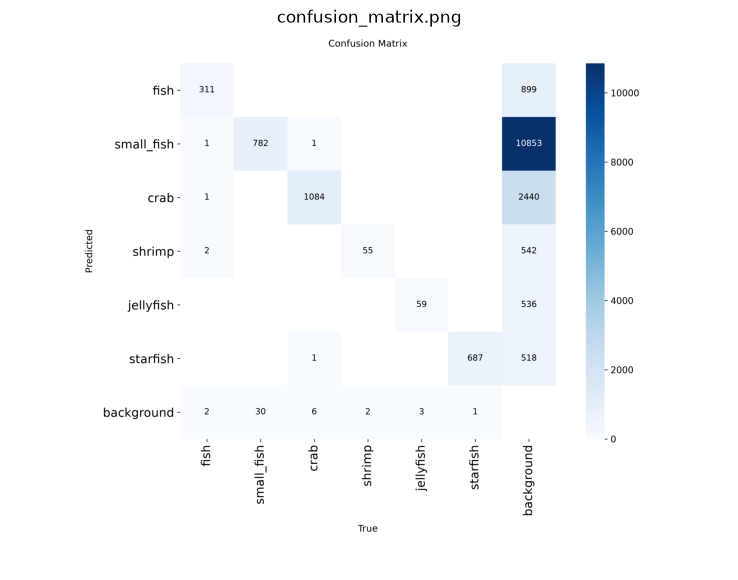

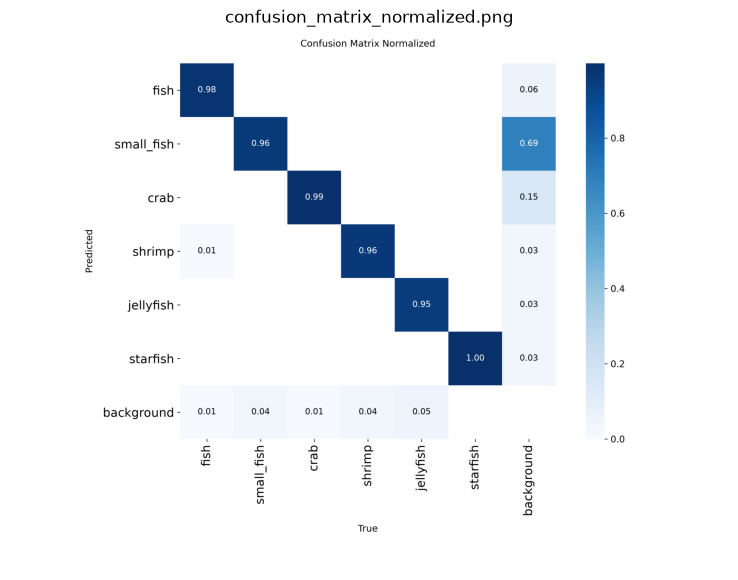

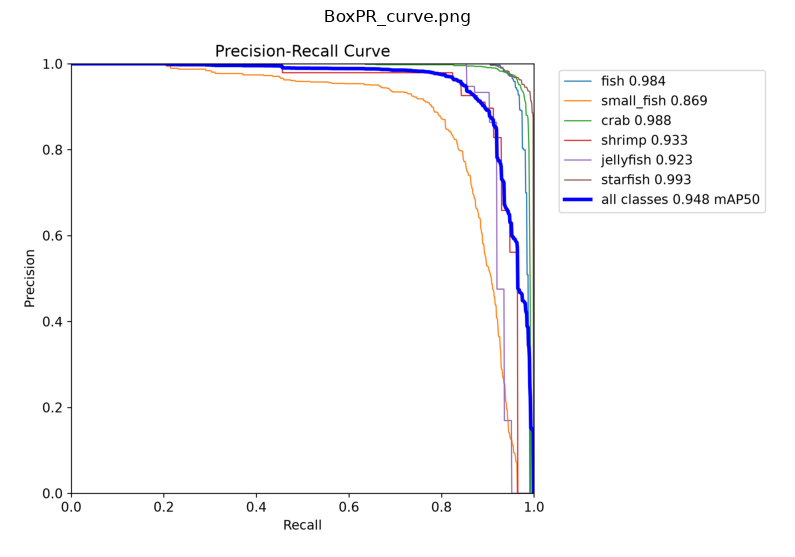

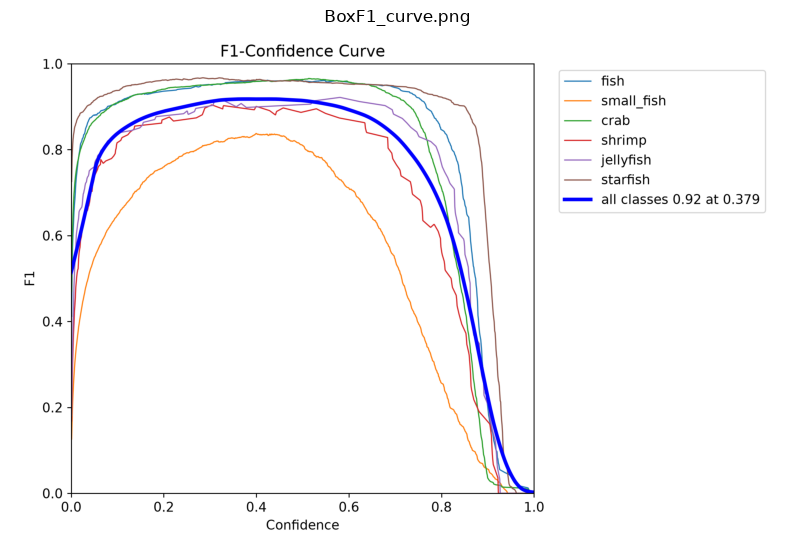

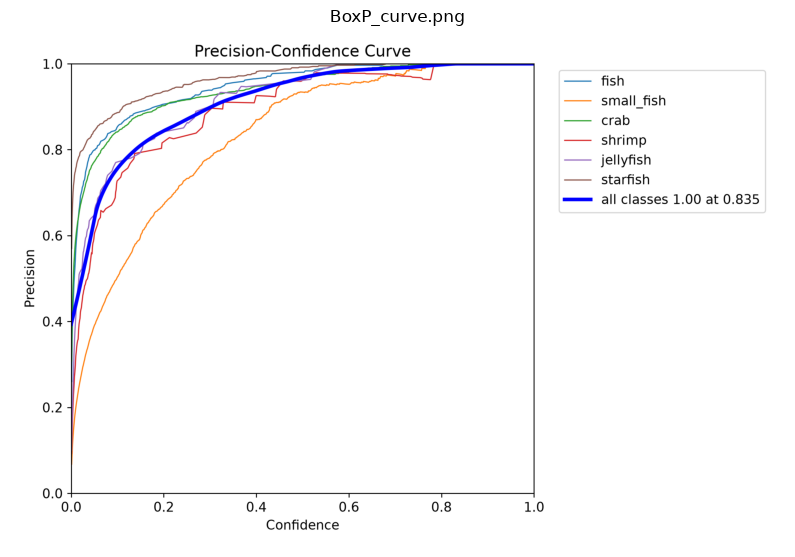

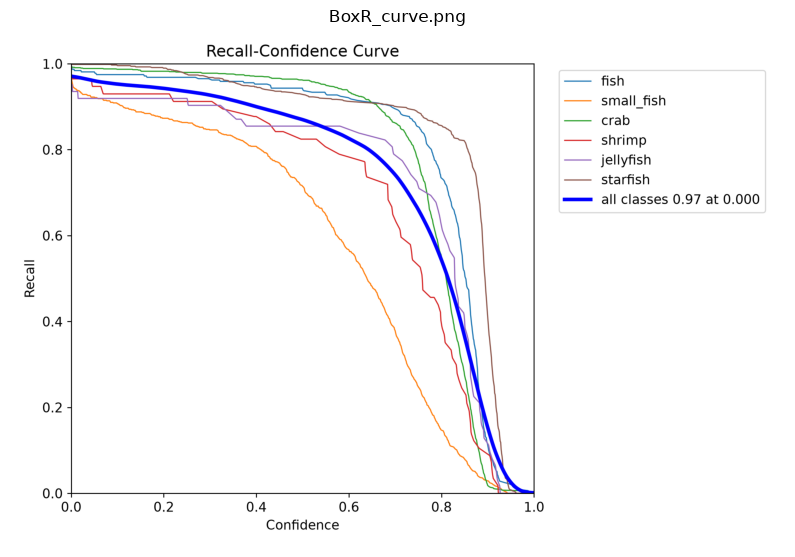

In [55]:
# Display the test evaluation plots

TEST_RESULTS_DIR = (
    PROJECT_ROOT / "runs" / "brackish_test_evaluation"
)

plots_to_show = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png"
]

for plot_name in plots_to_show:
    plot_path = TEST_RESULTS_DIR / plot_name

    if plot_path.exists():
        img = cv2.imread(str(plot_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(10, 7))
        plt.imshow(img)
        plt.title(plot_name)
        plt.axis("off")
        plt.show()
    else:
        print(f"Not found: {plot_name}")

## 8. Visualizing Model Predictions

This section demonstrates the trained YOLOv8n model on unseen test images.

The model predictions are visualized using bounding boxes, class labels, and confidence scores to assess the detection quality.

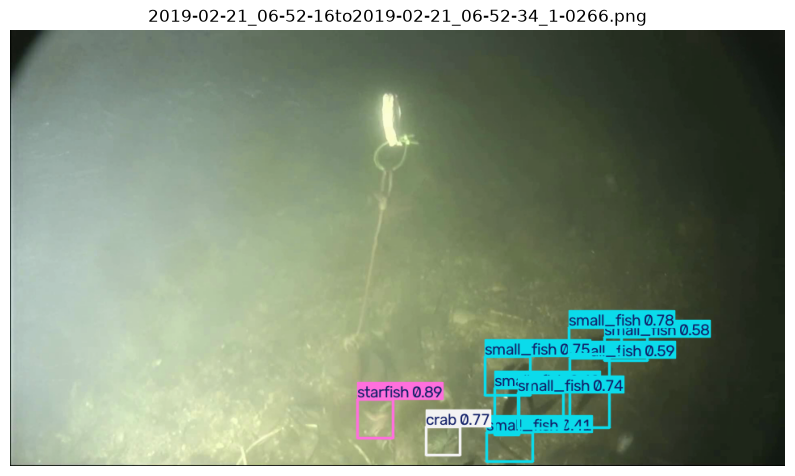

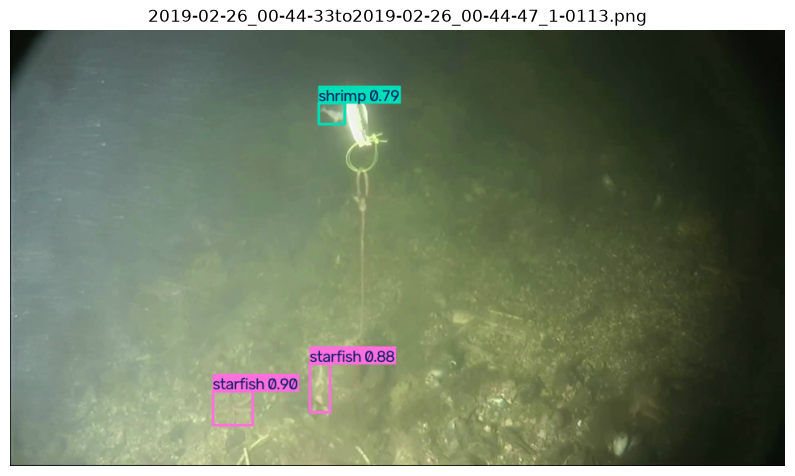

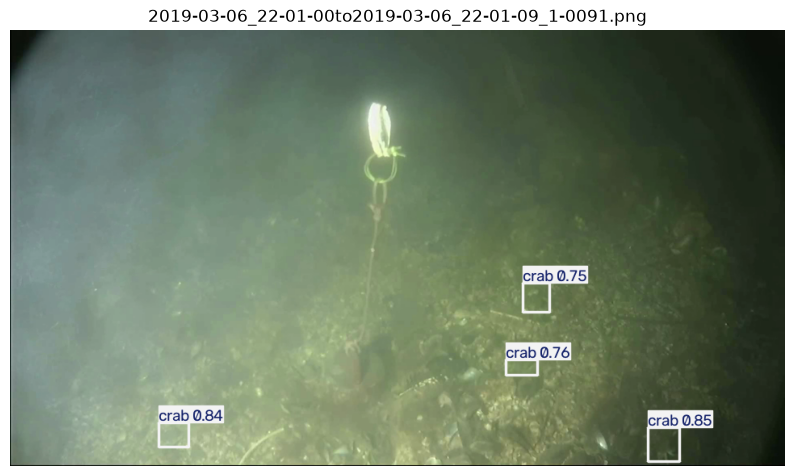

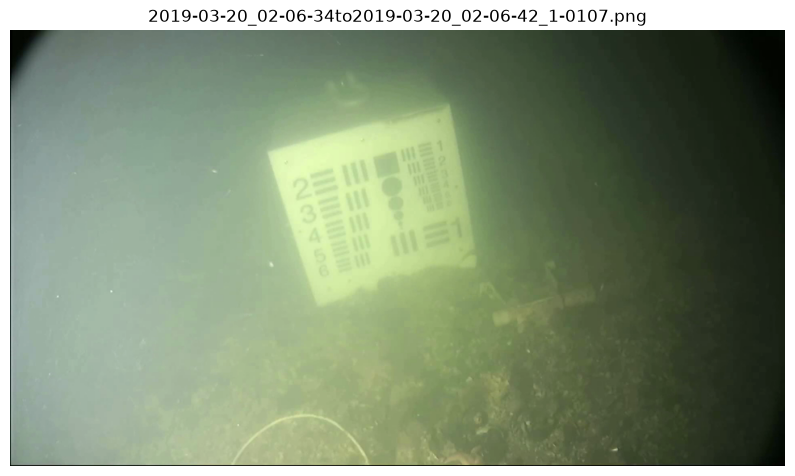

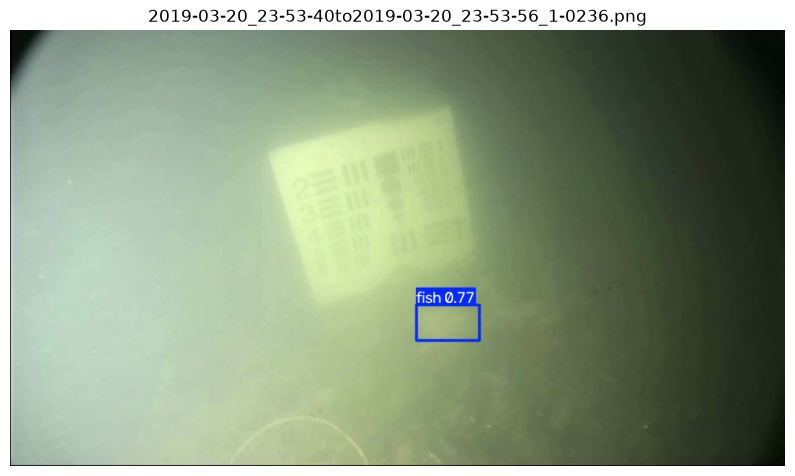

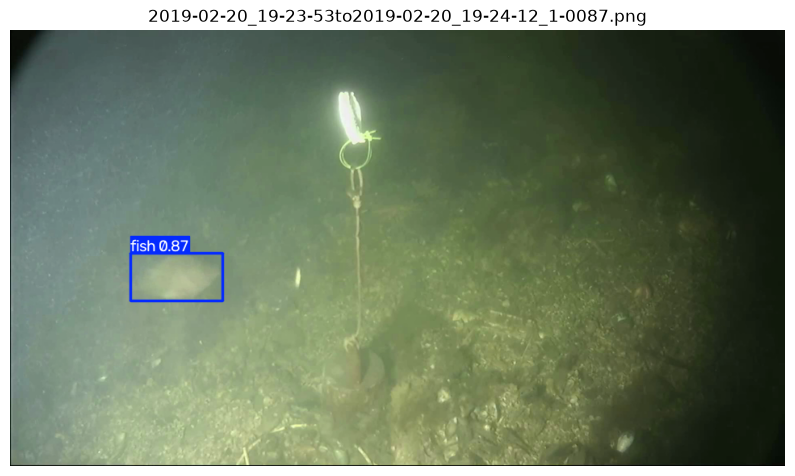

In [56]:
# Select random images from the test dataset

import random
import matplotlib.pyplot as plt
import cv2

TEST_IMAGES_DIR = PROJECT_ROOT / "data" / "processed" / "images" / "test"

test_images = list(TEST_IMAGES_DIR.glob("*"))

# Select 6 random test images
selected_images = random.sample(
    test_images,
    min(6, len(test_images))
)

# Run predictions
for image_path in selected_images:

    results = best_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )

    # Get annotated image
    annotated_image = results[0].plot()

    # Convert BGR to RGB
    annotated_image = cv2.cvtColor(
        annotated_image,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(10, 7))
    plt.imshow(annotated_image)
    plt.title(image_path.name)
    plt.axis("off")
    plt.show()

## 9. Ground Truth vs Model Predictions

This section compares the original ground truth annotations with the model's predictions on test images.

The comparison helps identify missed objects, false detections, and bounding box localization errors.

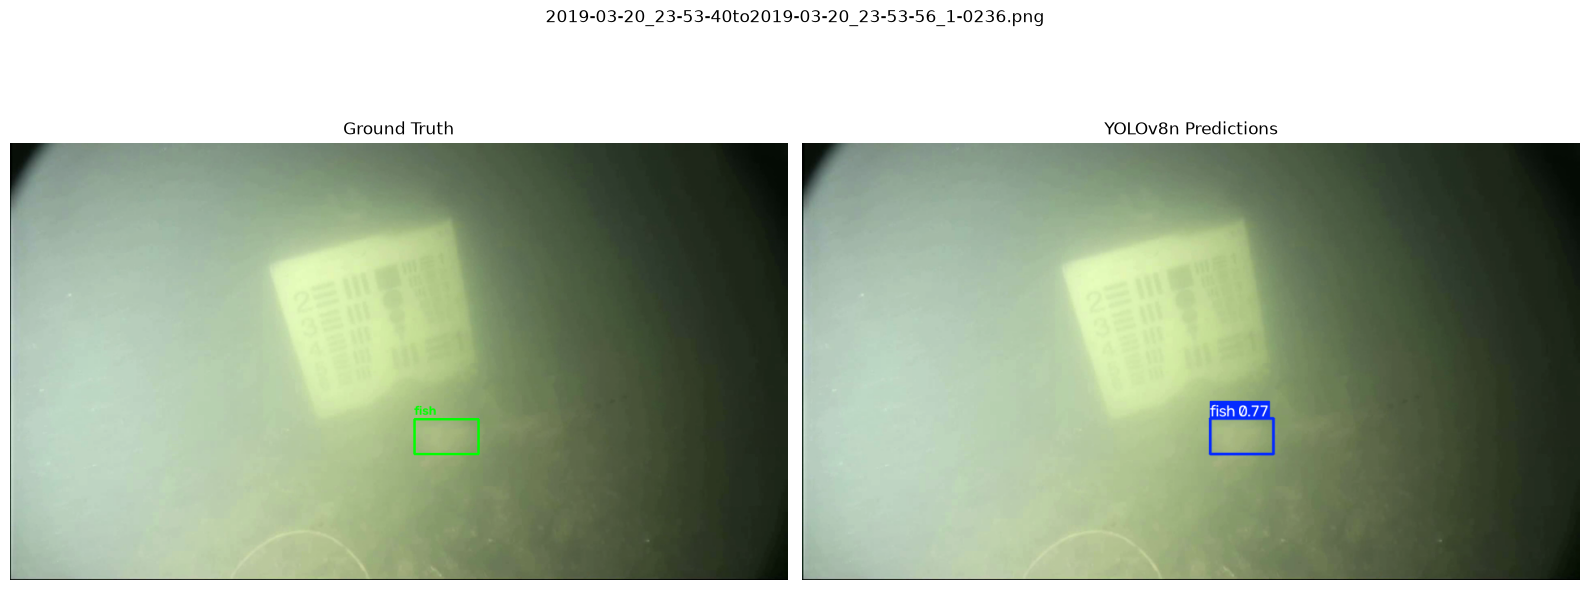

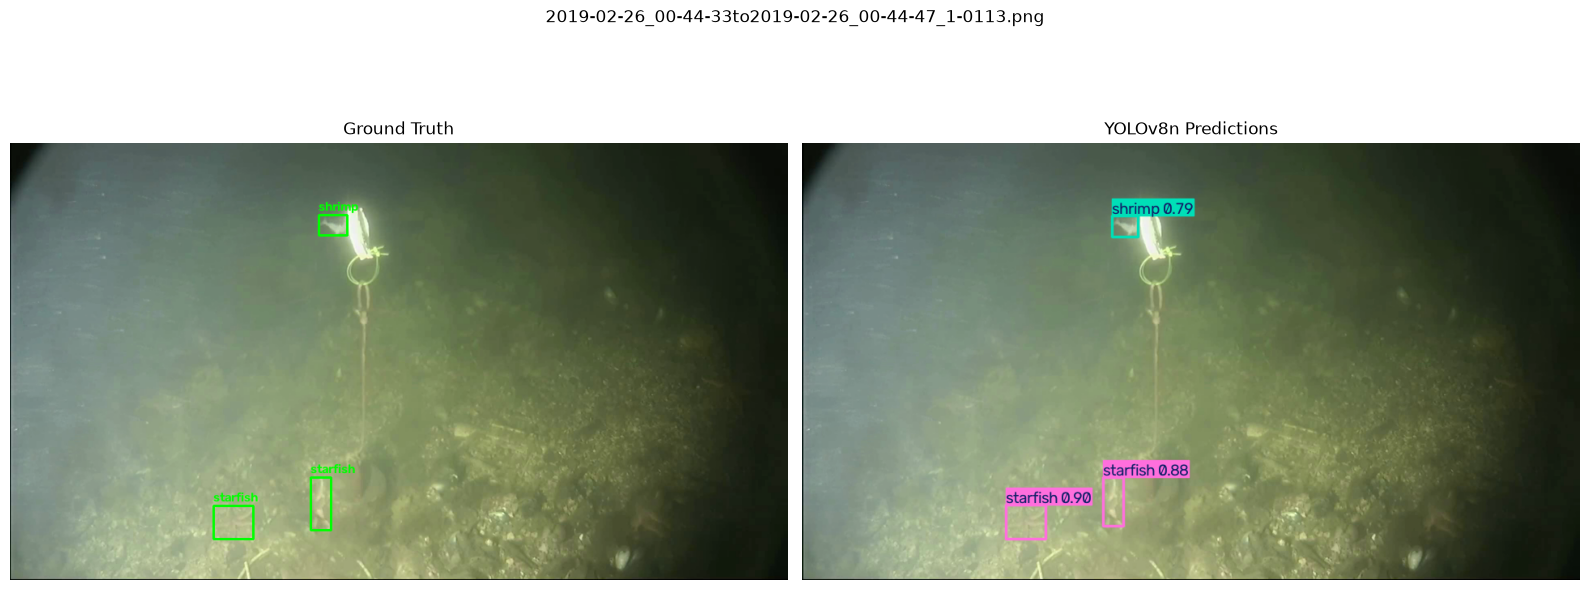

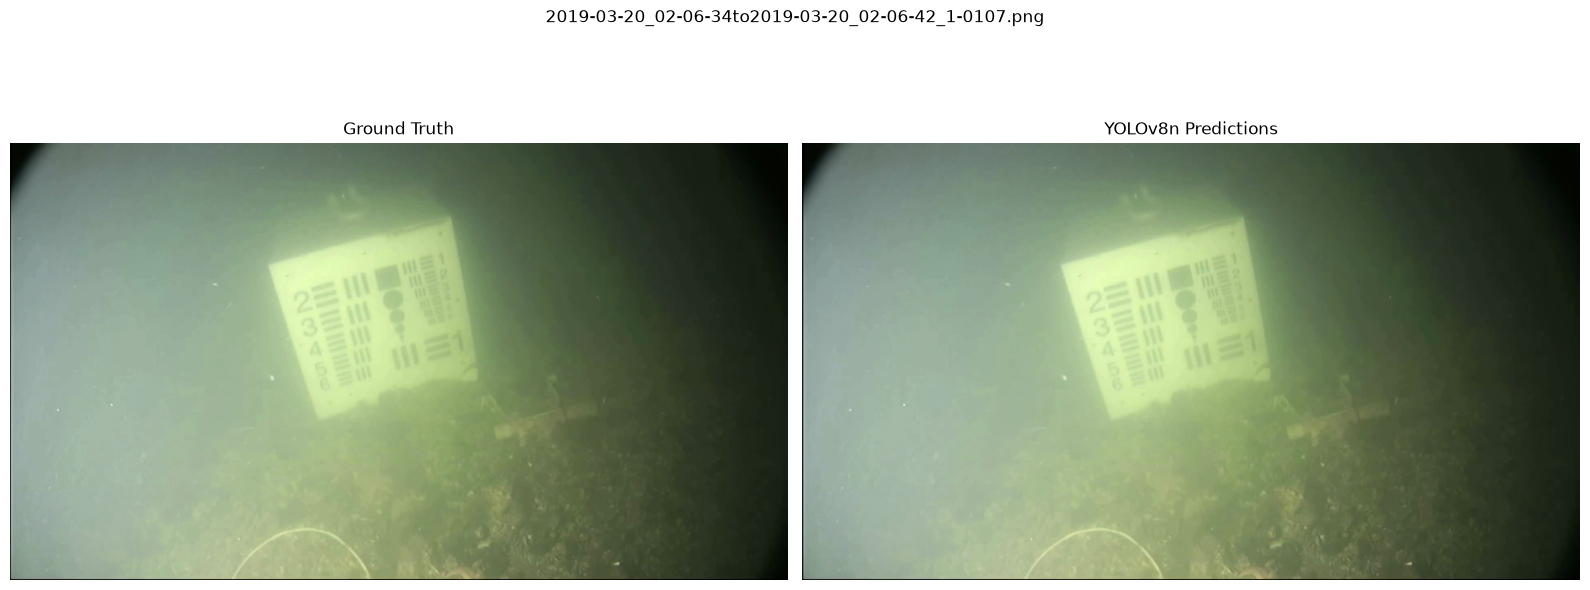

In [57]:
# Compare Ground Truth and Predictions

from PIL import Image

LABELS_TEST_DIR = PROJECT_ROOT / "data" / "processed" / "labels" / "test"

# Select 3 test images
comparison_images = random.sample(
    selected_images,
    min(3, len(selected_images))
)

for image_path in comparison_images:

    label_path = LABELS_TEST_DIR / f"{image_path.stem}.txt"

    # Load original image
    original = cv2.imread(str(image_path))
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

    h, w = original.shape[:2]

    # Draw Ground Truth boxes
    ground_truth = original.copy()

    if label_path.exists():
        with open(label_path, "r") as file:
            for line in file:
                values = line.strip().split()

                if len(values) != 5:
                    continue

                cls, xc, yc, bw, bh = map(float, values)

                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)

                cv2.rectangle(
                    ground_truth,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    2
                )

                class_name = best_model.names[int(cls)]

                cv2.putText(
                    ground_truth,
                    class_name,
                    (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 255, 0),
                    2
                )

    # Run model prediction
    prediction = best_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0].plot()

    prediction = cv2.cvtColor(
        prediction,
        cv2.COLOR_BGR2RGB
    )

    # Display side by side
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    axes[0].imshow(ground_truth)
    axes[0].set_title("Ground Truth")
    axes[0].axis("off")

    axes[1].imshow(prediction)
    axes[1].set_title("YOLOv8n Predictions")
    axes[1].axis("off")

    plt.suptitle(image_path.name)
    plt.tight_layout()
    plt.show()

## 10. Prediction Analysis

This section analyzes the number of detected objects and their confidence scores in selected test images.

It provides additional insight into the model's prediction behavior across different classes.

In [58]:
# Analyze predictions on selected test images

for image_path in comparison_images:

    result = best_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    print("\nImage:", image_path.name)
    print("Number of detected objects:", len(result.boxes))

    if len(result.boxes) > 0:
        for box in result.boxes:
            class_id = int(box.cls[0])
            class_name = best_model.names[class_id]
            confidence = float(box.conf[0])

            print(
                f"Class: {class_name:12s} | "
                f"Confidence: {confidence:.3f}"
            )
    else:
        print("No objects detected.")


Image: 2019-03-20_23-53-40to2019-03-20_23-53-56_1-0236.png
Number of detected objects: 1
Class: fish         | Confidence: 0.768

Image: 2019-02-26_00-44-33to2019-02-26_00-44-47_1-0113.png
Number of detected objects: 3
Class: starfish     | Confidence: 0.897
Class: starfish     | Confidence: 0.878
Class: shrimp       | Confidence: 0.795

Image: 2019-03-20_02-06-34to2019-03-20_02-06-42_1-0107.png
Number of detected objects: 0
No objects detected.


In [59]:
# Compare Ground Truth classes with predicted classes

for image_path in comparison_images:

    label_path = LABELS_TEST_DIR / f"{image_path.stem}.txt"

    print("\n" + "=" * 65)
    print("Image:", image_path.name)

    # Read Ground Truth labels
    ground_truth_classes = []

    if label_path.exists():
        with open(label_path, "r") as file:
            for line in file:
                values = line.strip().split()

                if len(values) == 5:
                    class_id = int(float(values[0]))
                    class_name = best_model.names[class_id]
                    ground_truth_classes.append(class_name)

    # Get model predictions
    result = best_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    predicted_classes = [
        best_model.names[int(box.cls[0])]
        for box in result.boxes
    ]

    print("Ground Truth:", ground_truth_classes)
    print("Predictions: ", predicted_classes)


Image: 2019-03-20_23-53-40to2019-03-20_23-53-56_1-0236.png
Ground Truth: ['fish']
Predictions:  ['fish']

Image: 2019-02-26_00-44-33to2019-02-26_00-44-47_1-0113.png
Ground Truth: ['shrimp', 'starfish', 'starfish']
Predictions:  ['starfish', 'starfish', 'shrimp']

Image: 2019-03-20_02-06-34to2019-03-20_02-06-42_1-0107.png
Ground Truth: []
Predictions:  []


### Ground Truth and Prediction Comparison

The model was tested on three randomly selected test images.

The comparison showed that:

- Image 1: The model correctly detected the fish.
- Image 2: The model correctly identified one shrimp and two starfish.
- Image 3: The model correctly predicted an empty background with no detected objects.

All three selected images showed matching ground truth and predicted class counts and labels.

This visual inspection provides an additional qualitative assessment of the trained model.

In [60]:

import numpy as np
import pandas as pd

# Evaluate Bounding Box Localization using IoU

def calculate_iou(box1, box2):
    # Boxes format: [x1, y1, x2, y2]

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


iou_results = []

for image_path in comparison_images:

    label_path = LABELS_TEST_DIR / f"{image_path.stem}.txt"

    image = cv2.imread(str(image_path))
    h, w = image.shape[:2]

    # Read Ground Truth boxes
    gt_boxes = []

    if label_path.exists():
        with open(label_path, "r") as file:
            for line in file:
                values = line.strip().split()

                if len(values) == 5:
                    cls, xc, yc, bw, bh = map(float, values)

                    x1 = (xc - bw / 2) * w
                    y1 = (yc - bh / 2) * h
                    x2 = (xc + bw / 2) * w
                    y2 = (yc + bh / 2) * h

                    gt_boxes.append({
                        "class_id": int(cls),
                        "box": [x1, y1, x2, y2]
                    })

    # Get predictions
    result = best_model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )[0]

    pred_boxes = []

    for box in result.boxes:
        pred_boxes.append({
            "class_id": int(box.cls[0]),
            "box": box.xyxy[0].cpu().numpy().tolist()
        })

    # Match boxes by class using highest IoU
    matched_ious = []
    used_predictions = set()

    for gt in gt_boxes:
        best_iou = 0
        best_index = None

        for i, pred in enumerate(pred_boxes):
            if i in used_predictions:
                continue

            if gt["class_id"] != pred["class_id"]:
                continue

            iou = calculate_iou(gt["box"], pred["box"])

            if iou > best_iou:
                best_iou = iou
                best_index = i

        if best_index is not None and best_iou >= 0.5:
            matched_ious.append(best_iou)
            used_predictions.add(best_index)

    mean_iou = np.mean(matched_ious) if matched_ious else 0

    iou_results.append({
        "Image": image_path.name,
        "Ground Truth": len(gt_boxes),
        "Predictions": len(pred_boxes),
        "Matched Boxes (IoU >= 0.5)": len(matched_ious),
        "Mean IoU": round(mean_iou, 4)
    })

iou_df = pd.DataFrame(iou_results)

display(iou_df)

print("\nOverall Mean IoU:",
      round(iou_df["Mean IoU"].mean(), 4))


,Image,Ground Truth,Predictions,Matched Boxes (IoU >= 0.5),Mean IoU
0,2019-03-20_23-53-40to2019-03-20_23-53-56_1-023...,1,1,1,0.9054
1,2019-02-26_00-44-33to2019-02-26_00-44-47_1-011...,3,3,3,0.8875
2,2019-03-20_02-06-34to2019-03-20_02-06-42_1-010...,0,0,0,0.0000



Overall Mean IoU: 0.5976


### Bounding Box Localization Evaluation

The model's bounding box localization was evaluated on three selected test images using Intersection over Union (IoU).

Results:

- Image 1 achieved an IoU of 0.9054.
- Image 2 achieved a mean IoU of 0.8875.
- All 4 ground truth objects across the two images containing objects were successfully matched with predictions at an IoU threshold of 0.5.
- Image 3 contained no objects in either the ground truth or predictions.

These results indicate accurate bounding box localization on the selected sample images.

In [61]:
# Check duplicate annotations in test labels

from collections import Counter

duplicate_count = 0
files_with_duplicates = []

for label_path in LABELS_TEST_DIR.glob("*.txt"):

    if not label_path.exists():
        continue

    with open(label_path, "r") as file:
        lines = [
            line.strip()
            for line in file
            if line.strip()
        ]

    counts = Counter(lines)
    duplicates = sum(
        count - 1
        for count in counts.values()
        if count > 1
    )

    if duplicates > 0:
        duplicate_count += duplicates
        files_with_duplicates.append(label_path.name)

print("Total duplicate annotations:", duplicate_count)
print("Files containing duplicates:", len(files_with_duplicates))
print("\nSample files:", files_with_duplicates[:10])

Total duplicate annotations: 0
Files containing duplicates: 0

Sample files: []


### Dataset Duplicate Annotation Check

A duplicate annotation check was performed on the test label files.

Results:
- Total duplicate annotations: 0
- Files containing duplicate annotations: 0

No identical duplicate annotation lines were found in the test labels.

This check supports the quality of the processed test annotations.

# 11. Conclusion

This project developed and trained a YOLOv8n object detection model from scratch to detect six marine object classes using the Brackish Dataset.

The dataset was prepared and validated using separate training, validation, and test splits. The model was initialized using the YOLOv8n architecture configuration without pretrained weights and trained for 50 epochs.

### Final Test Results

- Precision: 92.99%
- Recall: 90.46%
- mAP@50: 94.83%
- mAP@50-95: 70.32%

### Key Findings

- The model achieved strong overall detection performance on the independent test set.
- Starfish and crab achieved particularly strong detection results.
- Small fish was the most challenging class, with lower precision and localization performance.
- Prediction visualizations demonstrated successful detection across selected test images.
- Ground truth comparisons confirmed matching class labels and object counts in the selected samples.
- IoU evaluation showed accurate bounding box localization on the selected samples.
- No identical duplicate annotation lines were found in the test label files.

### Limitations and Future Improvements

- Improve small fish detection through further data analysis and targeted training.
- Investigate challenging images and possible overlapping detections.
- Evaluate localization performance across the complete test set.
- Explore data augmentation and hyperparameter tuning to improve generalization.

Overall, the project successfully demonstrates a custom-trained YOLOv8n object detection system for marine object detection.